# SImulations

In this notebook we simulate experiments to prove the efficacy of the Softmin Energy minimization method over other established global optimization methods.
The Softmin energy is defined as 
$$
    J_\beta(\mathbf{x}) = \sum_{i=1}^n \frac{e^{-\beta f (x_i)}f(x_i)}{\sum_{j=1}^n e^{-\beta f(x_j)}}
$$
with $\beta>0$, $\mathbf{x} = (x_1,\dots,x_n)$.

## Imports and utility functions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle as pkl

from tqdm import tqdm
from simulations import *
from potentials import *
from viz import plot_entry_time_comparison, plot_value_comparison, plot_prefactor_dynamics
import multiprocessing as mp

plt.rcParams['font.size'] = 15
#uncomment to double the fontsize in plots

N_CPU = mp.cpu_count()

# Paper figure typography (2026-09). Every figure below is included at 0.48\textwidth, so an
# 11x6in figure is reproduced roughly 3in wide -- at matplotlib's 10pt defaults the tick labels
# land near 3pt in print. use_paper_style() raises every font size and line width to survive that
# reduction; it sets global rcParams, so it applies to every figure produced later in this kernel.
from viz import use_paper_style

use_paper_style()


## Exit time from the maximizing regime

### Plot

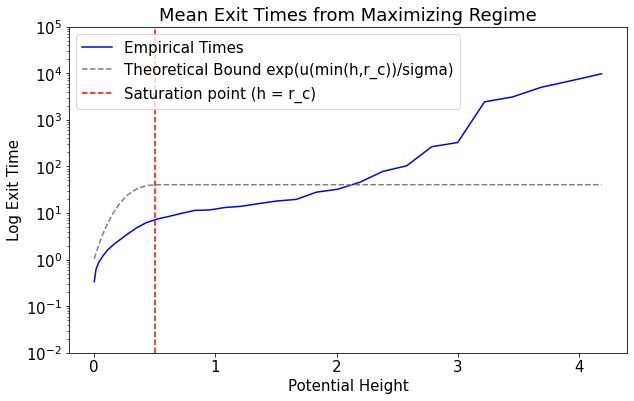

In [2]:
from scipy.optimize import brentq

noise = 0.05
beta = 2
n_particles = 100
tilt = 0.05  # matches TILT in run_theory_verification.py

def u(r, beta, n=n_particles):
    """Reduced potential along the frozen-background channel (Theorem 3.1, revised theory)."""
    return n * r * np.exp(-beta * r) / (n - 1 + np.exp(-beta * r))

def solve_r_c(beta, n=n_particles):
    """r_c = argmax u(r) = unique positive root of q(r) = (n-1)(1-beta*r) + exp(-beta*r)."""
    q = lambda r: (n - 1) * (1 - beta * r) + np.exp(-beta * r)
    return brentq(q, 1e-9, 50 / beta)

# beta and n are fixed for this whole sweep, so r_c is a single constant: the bound u(min(h, r_c))
# saturates once the physical barrier h exceeds r_c (Remark: "barrier saturates rather than
# growing with h").
r_c = solve_r_c(beta)

mean_exit_times, theory_bounds, x = [], [], []
q1_exit_times, q3_exit_times, std_exit_times = [], [], []

for delta in np.arange(0.25, 4.25, 0.125):
    # asymmetric_double_well is used both here (to compute h) and by run_theory_verification.py
    # (to generate exit_times below), so this overlay is a genuine apples-to-apples check against
    # Theorem 3.1's setup -- run `python run_theory_verification.py` on the cluster first if
    # results/softmin_static_double_well_init0_*.pkl don't exist yet.
    kwargs = asymmetric_double_well(delta, tilt)
    h = float(kwargs['f_vec']([kwargs['saddle']]) - kwargs['f_vec']([kwargs['z_start']]))
    if delta.is_integer(): delta = int(delta)
    string = f"softmin_static_double_well_init0_{delta}_{noise}".replace('.','p')+".pkl"
    with open(f"results/{string}", "rb") as f:
        exit_times = pkl.load(f)

    x.append(h)
    mean_exit_times.append(np.mean(exit_times))
    theory_bounds.append(np.exp(u(min(h, r_c), beta) / noise))

    std_exit_times.append(np.std(exit_times))
    q1_exit_times.append(np.percentile(exit_times, 25))
    q3_exit_times.append(np.percentile(exit_times, 75))

def get_asymmetric_errorbars(mean, q1, q3):
    lower = np.array(mean) - np.array(q1)
    upper = np.array(q3) - np.array(mean)
    return [np.maximum(lower, 0), np.maximum(upper, 0)]


fig, ax = plt.subplots(figsize=(10, 6))
err_exit_times = get_asymmetric_errorbars(mean_exit_times, q1_exit_times, q3_exit_times)
ax.plot(x, mean_exit_times, label='Empirical Times', color='blue')
ax.plot(x, theory_bounds, label='Theoretical Bound exp(u(min(h,r_c))/sigma)', color='gray', linestyle='--')
ax.vlines([r_c], ymin=1e-2, ymax=1e5, colors='red', linestyles='dashed', label='Saturation point (h = r_c)')
ax.set_yscale('log')
ax.set_ylim(1e-2, 1e5)
ax.set_xlabel('Potential Height')
ax.set_ylabel('Log Exit Time')
ax.set_title('Mean Exit Times from Maximizing Regime')
ax.legend()


**A note on what this bound actually claims.** Theorem 3.1 (`paper/SoftMin_revised_theory.tex`) is an *unconditional* bound on the Freidlin-Wentzell quasipotential, proved by exhibiting one admissible ("frozen-channel") path. Its connection to $E[\tau]$ is a **separate, explicitly conditional** corollary -- $\lim_{\sigma \to 0} \sigma \log E[\tau] = V_\beta \le u_h$ -- that depends on unverified metastable-domain hypotheses the paper's own text says it does not check. The overlay above compares raw $E[\tau]$ against $\exp(u_h/\sigma)$ at one fixed, non-vanishing $\sigma=0.05$, which conflates the proven log-asymptotic *rate* with an uncontrolled, $h$-dependent sub-exponential *prefactor* -- the empirical curve pulling away from the bound at high $h$ is expected under this framing, not evidence against the theorem. The cell below instead plots the quantity the theorem actually constrains -- $\sigma \log(\text{mean } \tau)$ -- which should stay bounded and trend toward $u_h$ as $\sigma \to 0$, reusing the sigma sweep already collected for the sensitivity study below (no new cluster run needed).


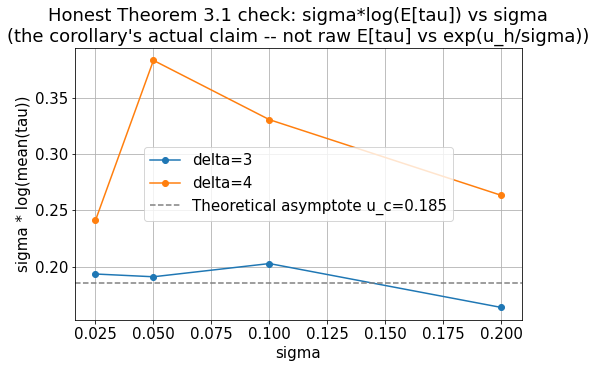

In [3]:
import os

from run_convergence_diagnostics import BASE_SIGMA

conv_csv = 'results/master_convergence_diagnostics.csv'

if os.path.exists(conv_csv):
    conv_df = pd.read_csv(conv_csv)
    u_c = u(r_c, beta, n_particles)  # the saturated bound value from the cell above

    def _sigma_series_with_baseline(df, base_value):
        axis = df[df['sweep'] == 'sigma']
        base = df[df['sweep'] == 'baseline'].copy()
        base['sigma'] = base_value
        return pd.concat([axis, base], ignore_index=True)

    fig, ax = plt.subplots(figsize=(8, 5))
    for delta in sorted(conv_df['delta'].unique()):
        d_df = conv_df[conv_df['delta'] == delta]
        sigma_df = _sigma_series_with_baseline(d_df, BASE_SIGMA)
        sigma_grouped = sigma_df.groupby('sigma')['tau'].mean().sort_index()
        ax.plot(sigma_grouped.index, sigma_grouped.index * np.log(sigma_grouped.values),
                marker='o', label=f'delta={delta}')

    ax.axhline(u_c, color='gray', linestyle='--', label=f'Theoretical asymptote u_c={u_c:.3f}')
    ax.set_xlabel('sigma')
    ax.set_ylabel('sigma * log(mean(tau))')
    ax.set_title('Honest Theorem 3.1 check: sigma*log(E[tau]) vs sigma\n(the corollary\'s actual claim -- not raw E[tau] vs exp(u_h/sigma))')
    ax.legend()
    ax.grid(True)
    fig.savefig('../paper/images/theory_verification_honest.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print(f"{conv_csv} not found -- run `python run_convergence_diagnostics.py` on the cluster "
          "first, then re-run this cell.")


## Sensitivity: Noise, Discretization Step, and Particle Count


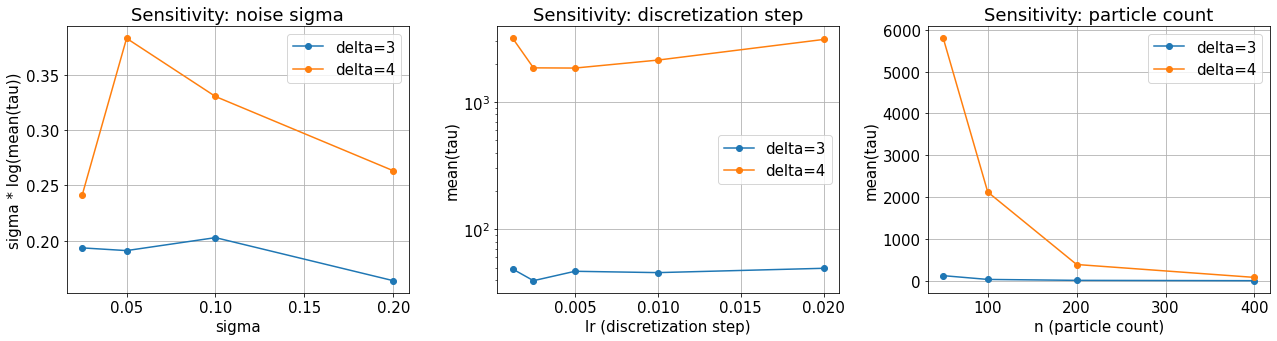

In [4]:
import os

import pandas as pd

from run_convergence_diagnostics import BASE_SIGMA, BASE_LR, BASE_N

# Reviewer demand (d): sigma/dt/n sensitivity, reading run_convergence_diagnostics.py's CSV
# directly (that driver deliberately writes no .pkl -- its natural unit is "one tau series per
# (sweep, delta, param)" across three different parameter axes, which doesn't fit
# reconstruct_pkl_files_from_csv's single-x-axis shape).
conv_csv = 'results/master_convergence_diagnostics.csv'

if os.path.exists(conv_csv):
    conv_df = pd.read_csv(conv_csv)

    def _series_with_baseline(df, sweep_name, param_col, base_value):
        """Rows for `sweep_name`, plus the shared 'baseline' rows relabeled to sit at
        `param_col=base_value` -- the deduplicated shared point (2026-08-07) is stored once,
        under its own 'baseline' sweep label, not inside every axis; see
        run_convergence_diagnostics.py's dedup comment."""
        axis = df[df['sweep'] == sweep_name]
        base = df[df['sweep'] == 'baseline'].copy()
        base[param_col] = base_value
        return pd.concat([axis, base], ignore_index=True)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for delta in sorted(conv_df['delta'].unique()):
        d_df = conv_df[conv_df['delta'] == delta]

        # sigma sweep: sigma*log(mean(tau)) vs sigma -- the empirical analogue of Theorem 3.1's
        # asymptotic statement lim_{sigma->0} sigma*log(E[tau]) = V_beta(...), which should
        # stabilize (not keep growing) as sigma shrinks if the theory's finite-size assumptions
        # hold at these deltas (both already in the saturated h>r_c regime, see cell 5 above).
        sigma_df = _series_with_baseline(d_df, 'sigma', 'sigma', BASE_SIGMA)
        sigma_grouped = sigma_df.groupby('sigma')['tau'].mean().sort_index()
        axes[0].plot(sigma_grouped.index, sigma_grouped.index * np.log(sigma_grouped.values),
                     marker='o', label=f'delta={delta}')

        # lr sweep: mean(tau) vs discretization step -- tau is already continuous physical time
        # (first_entry_time returns i*lr), so a genuine continuous-time limit should show this
        # roughly flattening as lr shrinks, not diverging.
        lr_df = _series_with_baseline(d_df, 'lr', 'lr', BASE_LR)
        lr_grouped = lr_df.groupby('lr')['tau'].mean().sort_index()
        axes[1].plot(lr_grouped.index, lr_grouped.values, marker='o', label=f'delta={delta}')

        # n sweep: mean(tau) vs particle count -- more particles should only ever help (more
        # independent attempts to be the one that escapes first).
        n_df = _series_with_baseline(d_df, 'n_particles', 'n', BASE_N)
        n_grouped = n_df.groupby('n')['tau'].mean().sort_index()
        axes[2].plot(n_grouped.index, n_grouped.values, marker='o', label=f'delta={delta}')

    axes[0].set_xlabel('sigma'); axes[0].set_ylabel('sigma * log(mean(tau))')
    axes[0].set_title('Sensitivity: noise sigma'); axes[0].legend(); axes[0].grid(True)

    axes[1].set_xlabel('lr (discretization step)'); axes[1].set_ylabel('mean(tau)')
    axes[1].set_yscale('log')
    axes[1].set_title('Sensitivity: discretization step'); axes[1].legend(); axes[1].grid(True)

    axes[2].set_xlabel('n (particle count)'); axes[2].set_ylabel('mean(tau)')
    axes[2].set_title('Sensitivity: particle count'); axes[2].legend(); axes[2].grid(True)

    plt.tight_layout()
    fig.savefig('../paper/images/theory_sensitivity.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print(f"{conv_csv} not found -- run `python run_convergence_diagnostics.py` on the cluster "
          "first, then re-run this cell.")


## 1 Dimensional Double Well Potential

### Plots

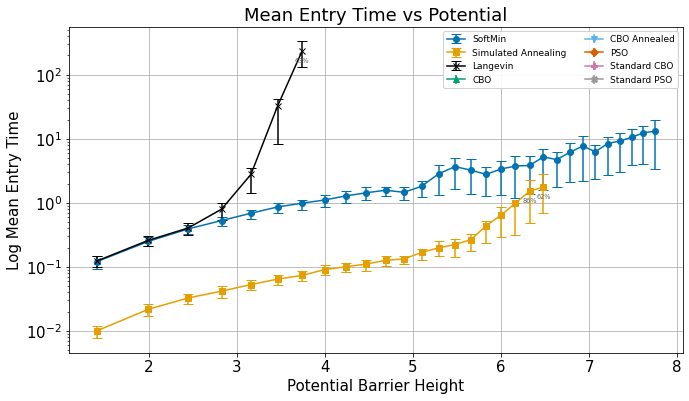

In [5]:
from run_experiments_resumable import DOUBLE_WELL_TILT, ALGO_NAMES as WELL_ALGO_NAMES
from viz import baseline_series

# x-axis is the TRUE barrier height f(saddle) - f(z_start), which is what the figure and the
# paper both claim to plot. It previously used critical_points[2] - critical_points[0], i.e.
# the distance between the two minima -- monotone in delta, so the qualitative story held, but
# off by two orders of magnitude (1.4->7.7 instead of 0.2->224.8) against an axis labelled
# 'Potential Barrier Height'.
x = []
for delta in range(1, 31):
    kwargs = asymmetric_double_well(delta, DOUBLE_WELL_TILT)
    f_vec = kwargs['f_vec']
    x.append(float(f_vec(np.array([kwargs['saddle']])) - f_vec(np.array([kwargs['z_start']]))))

# All 8 baselines (2026-08-07): CBO Annealed / Standard CBO / Standard PSO are the
# reviewer-requested fairness and gradient-free comparisons, Langevin is the fixed-noise control
# with no hyperparameter to tune -- see run_experiments_resumable.py. SoftMin Decay stays excluded
# (see Remark rem:higher-dim: a properly-tuned fixed beta consistently beat every decaying/growing
# schedule tested, gap widening at harder barriers).
#
# Masking is now status-based (status_filename_template), not a numeric mask_below cutoff: a run
# that never escapes can't drag a point's mean toward the max_steps*lr timeout sentinel. The old
# mask_below=1e4 silently stopped matching once MAX_STEPS/lr changed (plan's B3 finding) --
# status-based masking can't go stale the same way.
series = baseline_series(
    WELL_ALGO_NAMES, '{a}_double_well_{p}.pkl', '{a}_double_well_{p}_status.pkl',
)

fig, ax = plot_entry_time_comparison(
    min_reached_frac=0.5,
    x=x, results_dir='results', series=series, params=range(1, 31),
    xlabel='Potential Barrier Height', title='Mean entry time', grid=True,
)
fig.savefig('../paper/images/double_well_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


In [ ]:
# Reliability panel (2026-09) -- the companion to the entry-time cell above, and the TOP row of
# Figure fig:experiments in the paper. The entry-time plot reports a mean conditional on success
# and drops any point below min_reached_frac=0.5, so a method whose reliability collapses renders
# as a curve that simply STOPS. Read alone it invites the conclusion that SA beats Softmin, since
# SA's curve sits below Softmin's everywhere it is drawn at all. This panel plots every swept
# point with no cutoff, so the collapse is visible directly rather than by omission.
#
# Both panels load the same pkls through viz._load_point, so they cannot disagree about which
# seeds counted as successes.
from viz import baseline_series, plot_reached_fraction_comparison

# Legend BELOW the axes. On a reliability panel every in-axes position sits on top of a
# descending curve -- the descent is the entire content of the figure -- so an inside legend hides
# the result it labels. bbox_inches='tight' on savefig keeps it in the written image.
RELIABILITY_LEGEND = dict(loc='upper center', bbox_to_anchor=(0.5, -0.30), ncol=4, fontsize=12,
                          frameon=False, columnspacing=1.4, handletextpad=0.5)

# x-axis reuses the true-barrier-height list `x` built by the entry-time cell above, so the two
# panels of Figure fig:experiments share an x-axis by construction.
fig, ax = plot_reached_fraction_comparison(
    x=x, results_dir='results',
    series=baseline_series(
        WELL_ALGO_NAMES, '{a}_double_well_{p}.pkl', '{a}_double_well_{p}_status.pkl',
    ),
    params=range(1, 31), xlabel='Potential Barrier Height',
    title='Reliability', ylabel='Seeds reaching target (%)',
    as_percent=True, legend_kwargs=RELIABILITY_LEGEND,
)
fig.savefig('../paper/images/double_well_reliability.png', dpi=150, bbox_inches='tight')
plt.show()


## 2 Dimensional Quadruple Well Potential

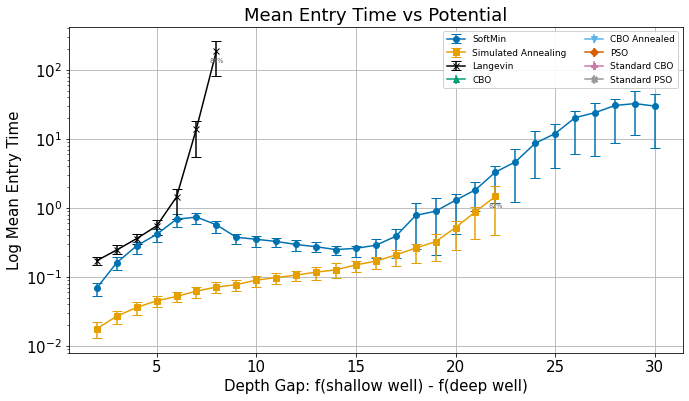

In [6]:
from run_experiments_resumable import ALGO_NAMES as WELL_ALGO_NAMES
from viz import baseline_series

# depth_gap = f(shallow diagonal well) - f(deep anti-diagonal well), replacing the pre-2026-08-07
# sorted-critical-f-value proxy (which relied on unbalanced_quadruple_well_setting's now-removed
# `critical_points` -- an expensive per-call sympy solve, dropped since nothing downstream read
# it once this figure's own x-axis was redesigned; see potentials.py). depth_gap grows linearly
# with A (exactly -A*delta = A at the fixed delta=-1, verified numerically).
#
# This also fixes B1/B1b: the benchmark's 'particle_init'/'set' were previously an EXACT mirror
# pair (identical depth, nothing suboptimal to escape from -- the same defect
# asymmetric_double_well's tilt term fixes for the 1D benchmark) due to a radius-formula bug.
# Fixed 2026-08-07: 'particle_init' now starts in the genuinely shallower diagonal well, 'set'
# targets the genuinely deeper anti-diagonal well. Pre-2026-08-07 quadruple_well results are not
# comparable to this figure.
x_ = [unbalanced_quadruple_well_setting(A, -1)['depth_gap'] for A in range(2, 31)]

# All 8 baselines (2026-08-07) -- CBO/PSO were previously excluded from this figure entirely,
# which is specifically what reviewer Ssem's Figure 1 (Middle) complaint was about. See the
# double-well cell above for the masking/baseline-set rationale (identical here).
series = baseline_series(
    WELL_ALGO_NAMES, '{a}_quadruple_well_{p}.pkl', '{a}_quadruple_well_{p}_status.pkl',
)

fig, ax = plot_entry_time_comparison(
    min_reached_frac=0.5,
    x=x_, results_dir='results', series=series, params=range(2, 31),
    xlabel='Depth gap', title='Mean entry time', grid=True,
)
fig.savefig('../paper/images/quadruple_well_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


In [ ]:
# Reliability panel (2026-09) -- the companion to the entry-time cell above, and the TOP row of
# Figure fig:experiments in the paper. The entry-time plot reports a mean conditional on success
# and drops any point below min_reached_frac=0.5, so a method whose reliability collapses renders
# as a curve that simply STOPS. Read alone it invites the conclusion that SA beats Softmin, since
# SA's curve sits below Softmin's everywhere it is drawn at all. This panel plots every swept
# point with no cutoff, so the collapse is visible directly rather than by omission.
#
# Both panels load the same pkls through viz._load_point, so they cannot disagree about which
# seeds counted as successes.
from viz import baseline_series, plot_reached_fraction_comparison

# Legend BELOW the axes. On a reliability panel every in-axes position sits on top of a
# descending curve -- the descent is the entire content of the figure -- so an inside legend hides
# the result it labels. bbox_inches='tight' on savefig keeps it in the written image.
RELIABILITY_LEGEND = dict(loc='upper center', bbox_to_anchor=(0.5, -0.30), ncol=4, fontsize=12,
                          frameon=False, columnspacing=1.4, handletextpad=0.5)

# x-axis reuses `x_` (depth gap) from the quadruple-well entry-time cell above.
fig, ax = plot_reached_fraction_comparison(
    x=x_, results_dir='results',
    series=baseline_series(
        WELL_ALGO_NAMES, '{a}_quadruple_well_{p}.pkl', '{a}_quadruple_well_{p}_status.pkl',
    ),
    params=range(2, 31), xlabel='Depth gap',
    title='Reliability', ylabel='Seeds reaching target (%)',
    as_percent=True, legend_kwargs=RELIABILITY_LEGEND,
)
fig.savefig('../paper/images/quadruple_well_reliability.png', dpi=150, bbox_inches='tight')
plt.show()


### Figure 1: combined 2x2 panel

The four well-benchmark panels composed into a single figure with ONE shared legend below all of
them, rather than four images each repeating the same eight-entry legend. This is what
`fig:experiments` in `paper/main.tex` includes.

The four standalone PNGs above are still written, unchanged, so the individual panels stay
available (slides, and any figure that wants one benchmark on its own). Note the OPT2026
submission is unaffected either way: `paper/Opt_submission/` carries its own separate `images/`
directory, which this notebook never writes to.


In [ ]:
import matplotlib.pyplot as plt

from viz import (baseline_series, plot_entry_time_comparison,
                 plot_reached_fraction_comparison, BASELINE_STYLE)

# Reuses x / x_ (barrier height, depth gap) and WELL_ALGO_NAMES from the cells above.
dw_series = baseline_series(
    WELL_ALGO_NAMES, '{a}_double_well_{p}.pkl', '{a}_double_well_{p}_status.pkl')
qw_series = baseline_series(
    WELL_ALGO_NAMES, '{a}_quadruple_well_{p}.pkl', '{a}_quadruple_well_{p}_status.pkl')

# Wider than tall per panel: this figure is included at \textwidth (figure*), not 0.48\textwidth,
# so it is reduced far less than the standalone panels and can afford a 2x2 grid.
fig, axes = plt.subplots(2, 2, figsize=(13, 8.2))

# Top row: reliability, every swept point, no cutoff. Bottom row: entry time, conditional on
# success. show_legend=False throughout -- one shared legend is added below instead.
plot_reached_fraction_comparison(
    x=x, results_dir='results', series=dw_series, params=range(1, 31),
    xlabel='Potential barrier height', ylabel='Seeds reaching target (%)',
    title='Double well: reliability', as_percent=True,
    ax=axes[0][0], show_legend=False)
plot_reached_fraction_comparison(
    x=x_, results_dir='results', series=qw_series, params=range(2, 31),
    xlabel='Depth gap', ylabel='Seeds reaching target (%)',
    title='Quadruple well: reliability', as_percent=True,
    ax=axes[0][1], show_legend=False)
plot_entry_time_comparison(
    min_reached_frac=0.5, x=x, results_dir='results', series=dw_series, params=range(1, 31),
    xlabel='Potential barrier height', ylabel='Mean entry time',
    title='Double well: entry time', grid=True,
    ax=axes[1][0], show_legend=False)
plot_entry_time_comparison(
    min_reached_frac=0.5, x=x_, results_dir='results', series=qw_series, params=range(2, 31),
    xlabel='Depth gap', ylabel='Mean entry time',
    title='Quadruple well: entry time', grid=True,
    ax=axes[1][1], show_legend=False)

# One shared legend for all four panels. Handles are taken from the bottom-left axis, which draws
# every series (the reliability panels draw the same eight, so either row would do); ordering
# follows BASELINE_STYLE via baseline_series, so it matches every other figure in the paper.
handles, labels = axes[1][0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, frameon=False,
           fontsize=14, columnspacing=2.0, handletextpad=0.6,
           bbox_to_anchor=(0.5, -0.02))

# rect leaves room at the bottom for the shared legend; without it tight_layout reclaims that
# space and the legend lands on top of the x-axis labels.
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig('../paper/images/well_benchmarks.png', dpi=150, bbox_inches='tight')
plt.show()


## Hgh Dimensional Ackley Function

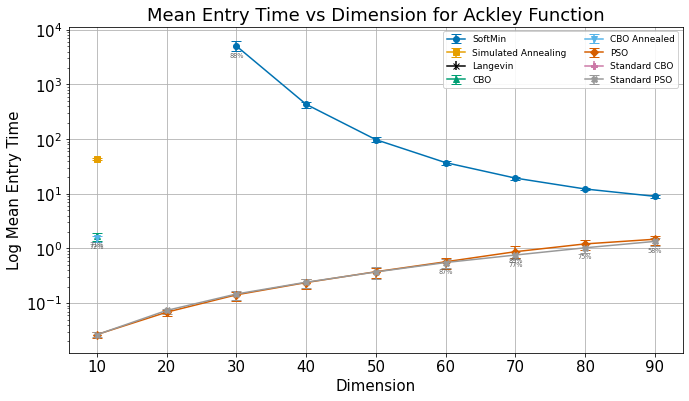

In [7]:
from run_ackley_dimensions import ALGO_NAMES as ACKLEY_ALGO_NAMES, FILENAME_BY_ALGO
from viz import baseline_series

x = list(range(10, 100, 10))

# All 8 baselines (2026-08-07), including Langevin -- see the double-well cell's comment for the
# general rationale. FILENAME_BY_ALGO is imported directly (not re-derived) since each algo's
# filename prefix is capitalized inconsistently (SoftMin_, CBO_, StandardCBO_, ...), not a uniform
# pattern -- re-deriving it here would risk silently drifting from what the driver actually
# writes. .removeprefix('results/') because plot_entry_time_comparison already joins results_dir.
_ackley_filenames = {a: t.replace('{dim}', '{p}').removeprefix('results/')
                      for a, t in FILENAME_BY_ALGO.items()}
series = baseline_series(
    ACKLEY_ALGO_NAMES, _ackley_filenames, '{a}_ackley_function_dim{p}_status.pkl',
)

fig, ax = plot_entry_time_comparison(
    min_reached_frac=0.5,
    x=x, results_dir='results', series=series,
    xlabel='Dimension', title='Ackley: entry time vs dimension', grid=True,
    legend_kwargs=dict(loc='upper center', bbox_to_anchor=(0.5, -0.30), ncol=4,
                       fontsize=12, frameon=False, columnspacing=1.4,
                       handletextpad=0.5),
)
fig.savefig('../paper/images/ackley_dimensions.png', dpi=150, bbox_inches='tight')
plt.show()


## Lennard-Jones Cluster Minimization

Real-physics, exact-gradient, NP-hard global-optimization benchmark (d=39..225, beyond the Ackley range above). Global minima are literature constants from the Cambridge Cluster Database (Wales & Doye 1997), `potentials.LJ_GLOBAL_MINIMA`. N=38 is the canonical hard double-funnel case (icosahedral local funnel vs. the true fcc-truncated-octahedron global minimum) -- see the driver's verification notes. Each algorithm's `first_value_time` hit time and the L-BFGS-B-quenched energy of its best configuration are both reported (see `run_lennard_jones.py`).

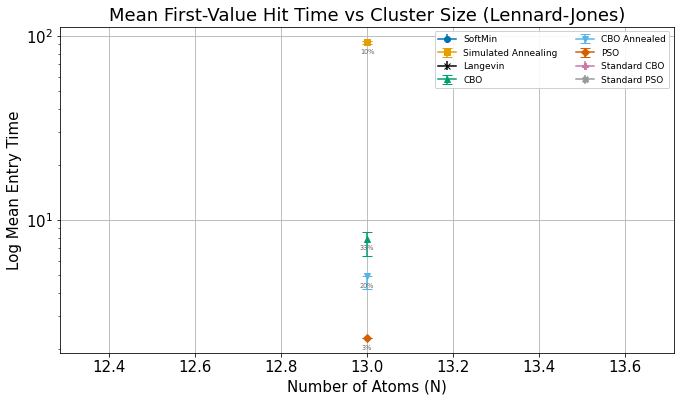

In [8]:
from run_lennard_jones import ALGO_NAMES as LJ_ALGO_NAMES
from viz import baseline_series

x = [13, 38, 55, 75]

series = baseline_series(
    LJ_ALGO_NAMES, '{a}_t_lennard_jones_n{p}.pkl', '{a}_status_lennard_jones_n{p}.pkl',
)

# min_reached_frac=0.0 (not the usual 0.5): at this strict, value-space hit-time target, almost
# no algorithm reaches it within budget at N>=38 (0% reached, every seed times out) -- a 0.5
# threshold would leave this panel empty. Shown at 0.0 so the honest, sparse picture (partial
# data only at N=13, where a minority of seeds do reach it) renders with its reached-fraction
# annotations rather than being suppressed; the quenched-energy-gap panel below is the
# informative comparison at N>=38, not this one -- see the paper prose.
fig, ax = plot_entry_time_comparison(
    min_reached_frac=0.0,
    x=x, results_dir='results', series=series,
    xlabel='Number of Atoms (N)', title='Lennard-Jones: hit time',
    grid=True,
    legend_kwargs=dict(loc='upper center', bbox_to_anchor=(0.5, -0.30), ncol=4,
                       fontsize=12, frameon=False, columnspacing=1.4,
                       handletextpad=0.5),
)
fig.savefig('../paper/images/lj_hit_time.png', dpi=150, bbox_inches='tight')
plt.show()


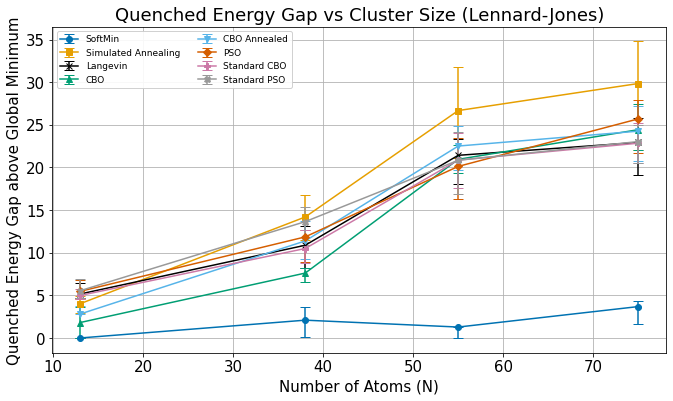

In [9]:
from run_lennard_jones import ALGO_NAMES as LJ_ALGO_NAMES
from viz import baseline_series

x = [13, 38, 55, 75]

series = baseline_series(LJ_ALGO_NAMES, '{a}_e_lennard_jones_n{p}.pkl')

# Subtract the literature global minimum (keyed by N) so the y-axis is a gap above the true
# optimum, comparable across cluster sizes -- not a raw (very negative) energy.
fig, ax = plot_value_comparison(
    x=x, results_dir='results', series=series,
    xlabel='Number of Atoms (N)', ylabel='Quenched energy gap',
    title='Lennard-Jones: quenched energy gap', grid=True,
    value_transform=lambda values, p: values - LJ_GLOBAL_MINIMA[p],
    legend_kwargs=dict(loc='upper center', bbox_to_anchor=(0.5, -0.30), ncol=4,
                       fontsize=12, frameon=False, columnspacing=1.4,
                       handletextpad=0.5),
)
fig.savefig('../paper/images/lj_energy_gap.png', dpi=150, bbox_inches='tight')
plt.show()


## Computational Cost Comparison

Evaluation-count-based cost comparison (gradient/objective oracle calls), per the reviewers' request for cost-matched comparisons rather than raw per-iteration counts. Fully local -- no cluster run needed.

In [ ]:
# Cost-to-solution (2026-09). The sweep-average columns alone invite a fair objection: a run that
# never escapes contributes its FULL step budget to the mean, so SA's 351.57 s partly measures how
# often it exhausts the budget, not a per-step cost difference. So we report three costs, and the
# three together are the honest picture:
#
#   sweep-average    -- what the appendix table has always reported.
#   solved-runs-only -- averaged over seeds with status 'target_reached'. On THIS column SA beats
#                       Softmin (~0.79 s vs 11.68 s): where SA works it really is cheaper, and the
#                       paper must say so.
#   ERT              -- expected running time, the BBOB/COCO standard (Hansen et al.): total cost
#                       over ALL seeds divided by the number of successes. Under a restart model
#                       this is the expected cost of the first success, so it is what a
#                       practitioner actually pays when they cannot know in advance which
#                       instances a method will solve. It is +inf where a method never succeeds.
#
# ERT is the column that fuses reliability and cost, and is computed per-difficulty below, where
# the Softmin/SA crossover is sharp.
import os
import numpy as np

from viz import BASELINE_STYLE
from run_experiments_resumable import ALGO_NAMES as WELL_ALGO_NAMES

cost_csv = 'results/master_experiment_log_decay.csv'

if os.path.exists(cost_csv):
    cost_df_raw = pd.read_csv(cost_csv)

    def _ert(sub, a, col):
        """Expected running time: total cost over all runs / number of successes (inf if none)."""
        n_ok = int((sub[f'{a}_status'] == 'target_reached').sum())
        return sub[f'{a}_{col}'].sum() / n_ok if n_ok else np.inf

    rows = []
    for a in WELL_ALGO_NAMES:
        ok = cost_df_raw[f'{a}_status'] == 'target_reached'
        rows.append((
            BASELINE_STYLE[a][0],
            cost_df_raw[f'{a}_gevals'].mean(),
            cost_df_raw[f'{a}_oevals'].mean(),
            cost_df_raw[f'{a}_secs'].mean(),
            cost_df_raw.loc[ok, f'{a}_secs'].mean() if ok.any() else np.nan,
            _ert(cost_df_raw, a, 'secs'),
            100.0 * ok.sum() / len(cost_df_raw),
        ))
    cost_df = pd.DataFrame(rows, columns=[
        'Method', 'Mean Gradient Evaluations (particle-steps)',
        'Mean Objective Evaluations (particle-steps)', 'Mean Wall-clock Time (s)',
        'Wall-clock, Solved Runs Only (s)', 'ERT Wall-clock (s)', 'Reached (%)',
    ])
    display(cost_df)

    # Per-difficulty ERT on the double well -- the numbers behind Table tab:cost_to_solution and
    # the crossover sentence in Section 6.1. SA is cheaper up to delta=15, then diverges.
    print('\nDouble-well ERT wall-clock (s), Softmin vs SA, by delta:')
    dw = cost_df_raw[cost_df_raw.experiment == 'double_well']
    for p in (5, 10, 15, 20, 25, 30):
        g = dw[dw.parameter == p]
        cells = []
        for a in ('softmin', 'sa'):
            n_ok = int((g[f'{a}_status'] == 'target_reached').sum())
            ert = _ert(g, a, 'secs')
            shown = 'never solved' if np.isinf(ert) else f'{ert:>12,.2f}s'
            cells.append(f'{a}: {shown} ({n_ok:3d}/{len(g)})')
        print(f'  delta={p:2d} | ' + ' | '.join(cells))
else:
    print(f"{cost_csv} not found -- run `python run_experiments_resumable.py` on the cluster "
          "first, then re-run this cell.")


## Ascent-Descent Dynamics

Illustrates the sign-changing effective learning rate $A_{t,k}$ (Section 2): particles below the Softmin threshold descend ($A_{t,k}>0$), particles above it ascend/explore ($A_{t,k}<0$). Fully local -- a short single-seed run, no cluster dependency.

2026-08-17 15:46:20 [INFO] Initialized Simulation '' with 20 particles in 1D space.


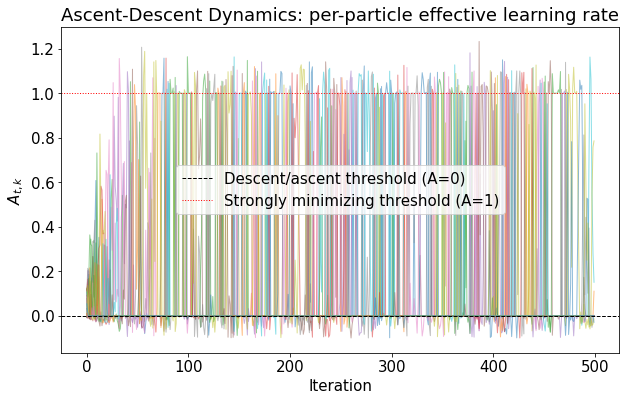

In [11]:
from run_experiments_resumable import DOUBLE_WELL_TILT

np.random.seed(0)
setting = asymmetric_double_well(4, DOUBLE_WELL_TILT)
demo_sim = SoftminEnergyAdagrad(
    n=20, d=1, f=setting['f_vec'], df=setting['f_grad_vec'],
    particle_init=setting['particle_init'], bounds=setting['bounds'],
    initial_lr=0.01, adaptive_lr=False, noise_intensity=1.0, beta=10.0,
    noise="normal", track_prefactor_history=True,
)
demo_sim.run(500)
fig, ax = plot_prefactor_dynamics(demo_sim)
fig.savefig('../paper/images/ascent_descent_dynamics.png', dpi=150, bbox_inches='tight')
plt.show()


## Ablation: Ascent-Descent Mechanism

Compares the real (signed) mechanism against two ablations from the revised theory's placeholder: replacing $A_{t,k}$ by $(A_{t,k})_+$ (ascending particles freeze) and by $|A_{t,k}|$ (every particle always descends). Kept separate from the SoftMin-vs-SA-vs-CBO-vs-PSO comparisons above. Needs `python run_ablation_experiment.py` run on the cluster first; the cell below prints a message instead of failing if that hasn't happened yet.

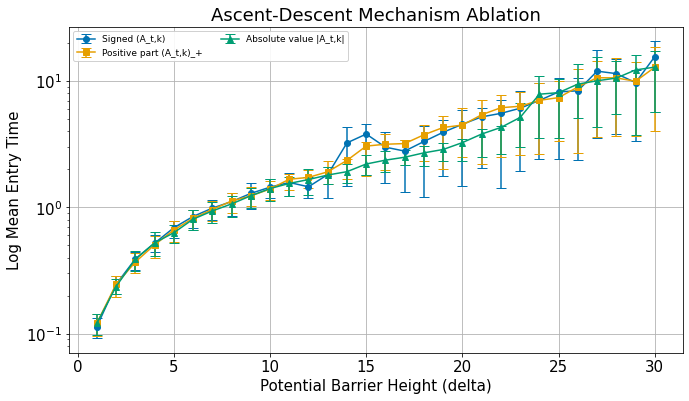

In [12]:
import os

ablation_dir = 'results'
sample_file = os.path.join(ablation_dir, 'ablation_signed_double_well_1.pkl')

if os.path.exists(sample_file):
    _ablation_style = {
        'signed': ('Signed (A_t,k)', '#0072B2', 'o'),
        'positive_part': ('Positive part (A_t,k)_+', '#E69F00', 's'),
        'absolute': ('Absolute value |A_t,k|', '#009E73', '^'),
    }
    ablation_series = [
        {'label': label, 'filename_template': f'ablation_{mode}_double_well_{{p}}.pkl',
         'status_filename_template': f'ablation_{mode}_double_well_{{p}}_status.pkl',
         'color': color, 'marker': marker}
        for mode, (label, color, marker) in _ablation_style.items()
    ]
    fig, ax = plot_entry_time_comparison(
        x=range(1, 31), results_dir=ablation_dir, series=ablation_series,
        xlabel='Potential barrier height', title='Ablation: double well', grid=True,
    )
    fig.savefig('../paper/images/ablation_double_well.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("Ablation results not found in 'results/' -- run `python run_ablation_experiment.py` "
          "on the cluster first, then re-run this cell.")


## Ablation Generalization: Quadruple-Well, Ackley, Lennard-Jones

The ablation above only tested the double-well benchmark. These three cells extend it to a 2D landscape (quadruple-well, full sweep -- cheap enough to match the double-well ablation's scope exactly), a high-dimensional landscape (Ackley, fixed at d=50, the driver's own diagnostic reference dimension), and a real-physics NP-hard landscape (Lennard-Jones, fixed at the canonical hard N=38 case). Each needs its own cluster run first (`python run_ablation_quadruple_well.py`, `run_ablation_ackley.py`, `run_ablation_lj.py`); each cell below prints a message instead of failing if that hasn't happened yet.


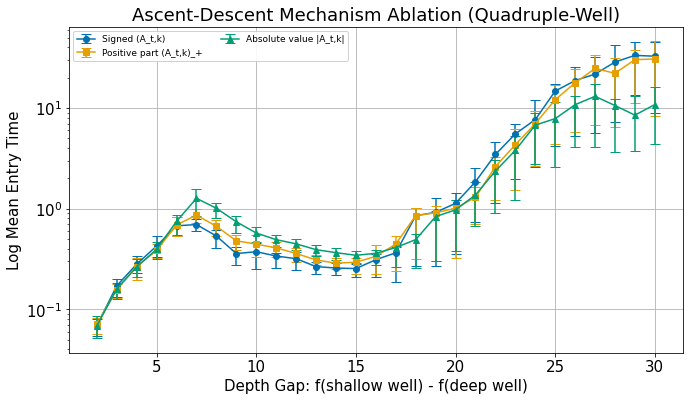

In [13]:
import os

qw_ablation_dir = 'results'
qw_sample_file = os.path.join(qw_ablation_dir, 'ablation_signed_quadruple_well_2.pkl')

if os.path.exists(qw_sample_file):
    _qw_ablation_style = {
        'signed': ('Signed (A_t,k)', '#0072B2', 'o'),
        'positive_part': ('Positive part (A_t,k)_+', '#E69F00', 's'),
        'absolute': ('Absolute value |A_t,k|', '#009E73', '^'),
    }
    qw_ablation_series = [
        {'label': label, 'filename_template': f'ablation_{mode}_quadruple_well_{{p}}.pkl',
         'status_filename_template': f'ablation_{mode}_quadruple_well_{{p}}_status.pkl',
         'color': color, 'marker': marker}
        for mode, (label, color, marker) in _qw_ablation_style.items()
    ]
    qw_x = [unbalanced_quadruple_well_setting(A, -1)['depth_gap'] for A in range(2, 31)]
    fig, ax = plot_entry_time_comparison(
        min_reached_frac=0.5,
        x=qw_x, results_dir=qw_ablation_dir, series=qw_ablation_series, params=range(2, 31),
        xlabel='Depth gap',
        title='Ablation: quadruple well', grid=True,
    )
    fig.savefig('../paper/images/ablation_quadruple_well.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("Quadruple-well ablation results not found in 'results/' -- run "
          "`python run_ablation_quadruple_well.py` on the cluster first, then re-run this cell.")


In [ ]:
import os

# Low-beta (beta=2) rerun of the quadruple-well ascent-descent ablation above (cell 27) --
# see run_ablation_beta2_quadruple_well.py. At beta=10 the Gibbs weight n*w_k concentrates
# sharply enough that the three prefactor_mode variants barely differ (paper's near-parity
# finding); beta=2 lets the sign convention's own effect show through directly, uncovering a
# crossover: absolute/positive part faster at small depth gaps, signed decisively faster once
# the barrier grows past a depth gap of about 10 (paper Figure ablation-quadruple-well-beta2).
# Uses the same unbalanced_quadruple_well_setting landscape as the beta=10 ablation (not the
# newer hybrid_quadruple_well_setting landscape investigated separately) -- both landscapes gave
# qualitatively the same crossover, so the cheaper, already-produced beta=10-landscape data is
# what's reported.
qw_beta2_ablation_dir = 'results'
qw_beta2_sample_file = os.path.join(qw_beta2_ablation_dir, 'ablation_signed_beta2_quadruple_well_2.pkl')

if os.path.exists(qw_beta2_sample_file):
    qw_beta2_x = [unbalanced_quadruple_well_setting(A, -1)['depth_gap'] for A in range(2, 21)]
    qw_beta2_series = [
        {'label': label, 'filename_template': f'ablation_{mode}_beta2_quadruple_well_{{p}}.pkl',
         'status_filename_template': f'ablation_{mode}_beta2_quadruple_well_{{p}}_status.pkl',
         'color': color, 'marker': marker}
        for mode, (label, color, marker) in _qw_ablation_style.items()
    ]
    fig, ax = plot_entry_time_comparison(
        min_reached_frac=0.5,
        x=qw_beta2_x, results_dir=qw_beta2_ablation_dir, series=qw_beta2_series, params=range(2, 21),
        xlabel='Depth gap',
        title='Ablation: quadruple well, beta=2', grid=True,
    )
    fig.savefig('../paper/images/ablation_quadruple_well_beta2.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("beta=2 quadruple-well ablation results not found in 'results/' -- run "
          "`python run_ablation_beta2_quadruple_well.py` locally first, then re-run this cell.")


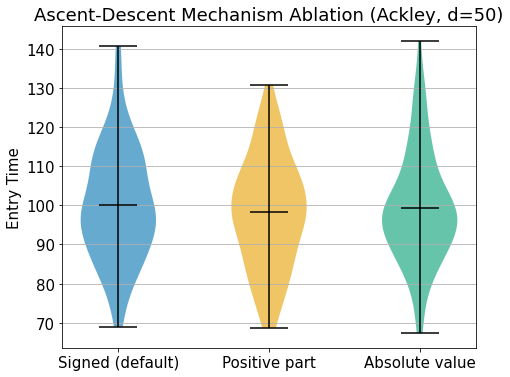

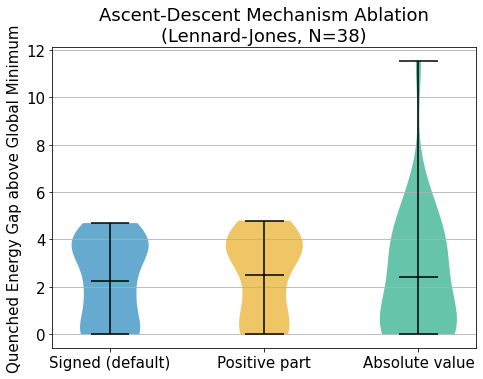

In [14]:
import os

import numpy as np

from viz import plot_mode_distribution

_ablation_modes = ['signed', 'positive_part', 'absolute']


def _load_mode_arrays(results_dir, filename_template, status_template=None):
    """Raw per-seed arrays per prefactor mode from a fixed-parameter ablation (single .pkl per
    mode, no parameter sweep) -- filtered to target_reached seeds when a status pkl is given,
    otherwise returned as-is (e.g. LJ's quenched energy, which is always well-defined regardless
    of whether the strict hit-time target was reached)."""
    datasets, reached_fracs = {}, {}
    for mode in _ablation_modes:
        with open(os.path.join(results_dir, filename_template.format(mode=mode)), 'rb') as f:
            values = np.asarray(pkl.load(f))
        if status_template is not None:
            with open(os.path.join(results_dir, status_template.format(mode=mode)), 'rb') as f:
                statuses = np.asarray(pkl.load(f))
            reached = statuses == 'target_reached'
            reached_fracs[mode] = float(np.mean(reached)) if reached.size else 0.0
            values = values[reached] if reached.any() else values
        datasets[mode] = values
    return datasets, reached_fracs


# --- Ackley, d=50 -----------------------------------------------------------------
# Violin plot (not bar+errorbar): all three modes turn out statistically indistinguishable here
# (100% reached, overlapping distributions) -- a single mean+/-IQR point per mode would visually
# overstate how separable they are, where the full distribution shows they're not.
ackley_sample = 'results/ablation_signed_ackley_dim50.pkl'
if os.path.exists(ackley_sample):
    ackley_datasets, _ = _load_mode_arrays(
        'results', 'ablation_{mode}_ackley_dim50.pkl', 'ablation_{mode}_ackley_dim50_status.pkl',
    )
    fig, ax = plot_mode_distribution(
        ackley_datasets, ylabel='Entry Time', kind='violin', figsize=(7, 5.5),
        title='Ablation: Ackley, d=50',
    )
    ax.grid(True, axis='y')
    fig.savefig('../paper/images/ablation_ackley_dim50.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("Ackley ablation results not found in 'results/' -- run `python run_ablation_ackley.py` "
          "on the cluster first, then re-run this cell.")

# --- Lennard-Jones, N=38 -----------------------------------------------------------
# Quenched-energy-gap distribution only (violin plot): the hit-rate panel is dropped here --
# at N=38 essentially no seed under any mode reaches the strict hit-time target within budget
# (0% reached_frac across all three modes), so a hit-rate bar chart there would just be three
# bars at zero. Quenched energy is always well-defined (no gating on reaching a target) and is
# the metric that actually distinguishes the modes at this scale.
lj_sample = 'results/ablation_signed_e_lennard_jones_n38.pkl'
if os.path.exists(lj_sample):
    lj_datasets, _ = _load_mode_arrays('results', 'ablation_{mode}_e_lennard_jones_n38.pkl')
    lj_gap_datasets = {m: v - LJ_GLOBAL_MINIMA[38] for m, v in lj_datasets.items()}
    fig, ax = plot_mode_distribution(
        lj_gap_datasets, ylabel='Quenched energy gap', kind='violin',
        figsize=(7, 5.5), title='Ablation: Lennard-Jones, N=38',
    )
    ax.grid(True, axis='y')
    fig.savefig('../paper/images/ablation_lj_n38.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("Lennard-Jones ablation results not found in 'results/' -- run "
          "`python run_ablation_lj.py` on the cluster first, then re-run this cell.")


## Hyperparameter Sensitivity: Softmin Beta


In [15]:
import os

import pandas as pd

# Reviewer demand (d): the beta-sensitivity study behind Softmin's shipped beta=10 (see
# hyperparameter_diagnostics.py) is now persisted to CSV via write_escape_results_csv, instead of
# stdout-only -- citable directly from this cell rather than needing to re-run that script and
# read terminal output.
beta_csv = 'results/hyperparameter_diagnostics_beta_sweep.csv'

if os.path.exists(beta_csv):
    beta_df = pd.read_csv(beta_csv)
    fig, ax = plt.subplots(figsize=(10, 6))
    for benchmark in beta_df['benchmark'].unique():
        sub = beta_df[beta_df['benchmark'] == benchmark]
        ax.scatter(sub['candidate'], sub['entry_time'], label=benchmark, s=60)
    ax.set_xlabel('beta candidate (fixed value or annealing schedule)')
    ax.set_ylabel('entry_time')
    ax.set_yscale('log')
    ax.set_title('Softmin Beta Sensitivity (double_well / quadruple_well / Ackley midpoints)')
    ax.legend()
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print(f"{beta_csv} not found -- run `python hyperparameter_diagnostics.py` first, then "
          "re-run this cell.")


results/hyperparameter_diagnostics_beta_sweep.csv not found -- run `python hyperparameter_diagnostics.py` first, then re-run this cell.


## Ensemble-size (particle-count) sweep

Softmin vs. Simulated Annealing on the 2D quadruple well as the ensemble size `n` varies, at three
difficulties spanning SA's reliability collapse. Requires `python run_particle_sweep.py`
(or `sbatch jobs/run_particle_sweep.sh`) to have been run first.

SA here is `n` *independent* annealed chains, so raising `n` hands it more restarts too: the
comparison asks whether Softmin's ensemble coupling buys anything beyond embarrassingly-parallel
restarts at matched cost.


In [ ]:
import os

import numpy as np
import matplotlib.pyplot as plt

from run_particle_sweep import N_VALUES, A_VALUES, ALGO_NAMES as SWEEP_ALGOS
from viz import _load_point

SWEEP_CSV = 'results/master_particle_sweep.csv'

if not os.path.exists(SWEEP_CSV):
    print(f"{SWEEP_CSV} not found -- run `python run_particle_sweep.py` on the cluster first.")
else:
    # One color per algorithm, one linestyle per difficulty, so the two factors stay separable.
    ALGO_COLOR = {'softmin': '#0072B2', 'sa': '#E69F00'}
    ALGO_LABEL = {'softmin': 'SoftMin', 'sa': 'Simulated Annealing'}
    A_STYLE = {A: ls for A, ls in zip(A_VALUES, ['-', '--', ':'])}

    def series_for(algo, A):
        return {'filename_template': f'{algo}_quadruple_well_{A}_n{{p}}.pkl',
                'status_filename_template': f'{algo}_quadruple_well_{A}_n{{p}}_status.pkl'}

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
    for algo in SWEEP_ALGOS:
        for A in A_VALUES:
            s = series_for(algo, A)
            reached, entry, cost = [], [], []
            for n in N_VALUES:
                times, mask, frac = _load_point('results', s, n)
                reached.append(100.0 * frac)
                # Entry time and cost are conditional on success, and undefined with no successes.
                entry.append(np.mean(times[mask]) if mask.any() else np.nan)
                # Total per-particle gradient work scales with n by construction, so this panel
                # answers "what does the extra reliability cost?" rather than repeating panel 1.
                cost.append(n * np.mean(times[mask]) / 0.001 if mask.any() else np.nan)
            kw = dict(color=ALGO_COLOR[algo], linestyle=A_STYLE[A], marker='o', markersize=4,
                      label=f'{ALGO_LABEL[algo]} (gap {A})')
            axes[0].plot(N_VALUES, reached, **kw)
            axes[1].plot(N_VALUES, entry, **kw)
            axes[2].plot(N_VALUES, cost, **kw)

    for ax, ylab, ysc in ((axes[0], 'Seeds reaching target (%)', 'linear'),
                          (axes[1], 'Mean entry time (successes only)', 'log'),
                          (axes[2], 'Per-particle gradient evals to target', 'log')):
        ax.set_xlabel('Ensemble size $n$')
        ax.set_ylabel(ylab)
        ax.set_xscale('log')
        ax.set_yscale(ysc)
        ax.grid(alpha=0.3)
    axes[0].set_ylim(-2, 102)
    axes[0].legend(fontsize=8, ncol=1)
    fig.tight_layout()
    fig.savefig('../paper/images/particle_sweep.png', dpi=150, bbox_inches='tight')
    plt.show()


## Transformer training benchmark

Optimizing a small decoder-only transformer's training loss on modular addition, at increasing
depth (see `nn_objective.py`). Requires `sbatch jobs/run_transformer.sh` to have been run first --
this is the one driver in the project that needs a GPU.

Headline metric is reliability (fraction of seeds reaching the target loss) vs. depth, matching the
analytic benchmarks; best loss reached and wall-clock are reported alongside.


In [ ]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from run_transformer import DEPTHS, ALGO_NAMES as TF_ALGOS, N_SEEDS
from viz import BASELINE_STYLE

TF_CSV = 'results/master_transformer.csv'

if not os.path.exists(TF_CSV):
    print(f"{TF_CSV} not found -- run `sbatch jobs/run_transformer.sh` on the cluster first.")
else:
    tf = pd.read_csv(TF_CSV)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))

    for a in TF_ALGOS:
        label, color, marker = BASELINE_STYLE[a]
        reached, best = [], []
        for d in DEPTHS:
            g = tf[tf.depth == d]
            reached.append(100.0 * (g[f'{a}_status'] == 'target_reached').mean() if len(g) else np.nan)
            best.append(g[f'{a}_best'].mean() if len(g) else np.nan)
        axes[0].plot(DEPTHS, reached, marker=marker, color=color, label=label)
        axes[1].plot(DEPTHS, best, marker=marker, color=color, label=label)

    axes[0].set_ylabel(f'Seeds reaching target loss (%), n={N_SEEDS}')
    axes[0].set_ylim(-2, 102)
    # Entry time is logged in STEPS here, not steps x eta -- the methods do not share a
    # learning rate on this benchmark (see run_transformer.py's note), so eta is not a
    # common clock. Steps are comparable: one objective and one gradient evaluation per
    # particle per step for every method.
    axes[1].set_ylabel('Best training loss reached')
    axes[1].set_yscale('log')
    for ax in axes:
        ax.set_xlabel('Transformer depth (layers)')
        # Log x-axis: the sweep spans 2 to 50 layers, so a linear axis would crush the shallow
        # half of it against the origin. Ticks are labelled with the actual depths, not powers.
        ax.set_xscale('log')
        ax.set_xticks(DEPTHS)
        ax.set_xticklabels([str(d) for d in DEPTHS])
        ax.minorticks_off()
        ax.grid(alpha=0.3)
    axes[0].legend(fontsize=8, ncol=2)
    fig.tight_layout()
    fig.savefig('../paper/images/transformer_depth.png', dpi=150, bbox_inches='tight')
    plt.show()
